# Colorization: fidelity, diversity and ambiguous predictions
        Investigate grayscale/L2/transfer/balanced-bin predictions together.
        [Protocols and interpretation](../docs/11_image_restoration.md).
        Photos retain their [source attribution](../docs/photo_attributions.md).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
import torch
from learning_lab.restoration import rgb_to_lab, lab_to_rgb
rgb = torch.tensor([[[[1.]],[[0.]],[[0.]]]])
lab = rgb_to_lab(rgb)
print('D65 red CIELAB:',lab[0,:,0,0].numpy()*[100,110,110])
torch.testing.assert_close(lab_to_rgb(lab),rgb,atol=3e-6,rtol=0)

D65 red CIELAB: [53.24079394 80.0924623  67.2031945 ]


## A simple ambiguity example
        Two opposite chroma hypotheses with equal probability have a zero-chroma conditional
        mean. That prediction minimizes expected L2 error, even if it looks desaturated.

In [3]:
hypotheses = np.array([[40.,20.],[-40.,-20.]])
mean_chroma = hypotheses.mean(0)
print('Conditional mean:',mean_chroma)
print('Expected squared error of mean:',np.mean(np.sum((hypotheses-mean_chroma)**2,axis=1)))
print('Expected squared error of one hypothesis:',np.mean(np.sum((hypotheses-hypotheses[0])**2,axis=1)))

Conditional mean: [0. 0.]
Expected squared error of mean: 2000.0
Expected squared error of one hypothesis: 4000.0


In [4]:
m = evidence('colorization')
pd.DataFrame([{'model':r['model'],'seed':r.get('seed'),'psnr':r['psnr']['mean'],
              'delta_e76':r['delta_e76']['mean'],'chroma':r['mean_chroma']['mean'],
              'true_chroma':r['true_mean_chroma']} for r in m['rows']])

,model,seed,psnr,delta_e76,chroma,true_chroma
0,neutral_gray,NaN,25.311615,15.964154,0.000000,15.964153
1,autoencoder_l2,0.0,23.387108,14.378936,9.291015,15.964153
2,transfer_l2,0.0,23.777885,13.776851,10.681240,15.964153
3,transfer_balanced_bins,0.0,22.950842,15.551892,14.372451,15.964153
4,autoencoder_l2,1.0,23.379766,14.423375,8.899590,15.964153
5,transfer_l2,1.0,23.564901,14.223806,10.832904,15.964153
6,transfer_balanced_bins,1.0,22.885869,15.443452,14.152438,15.964153


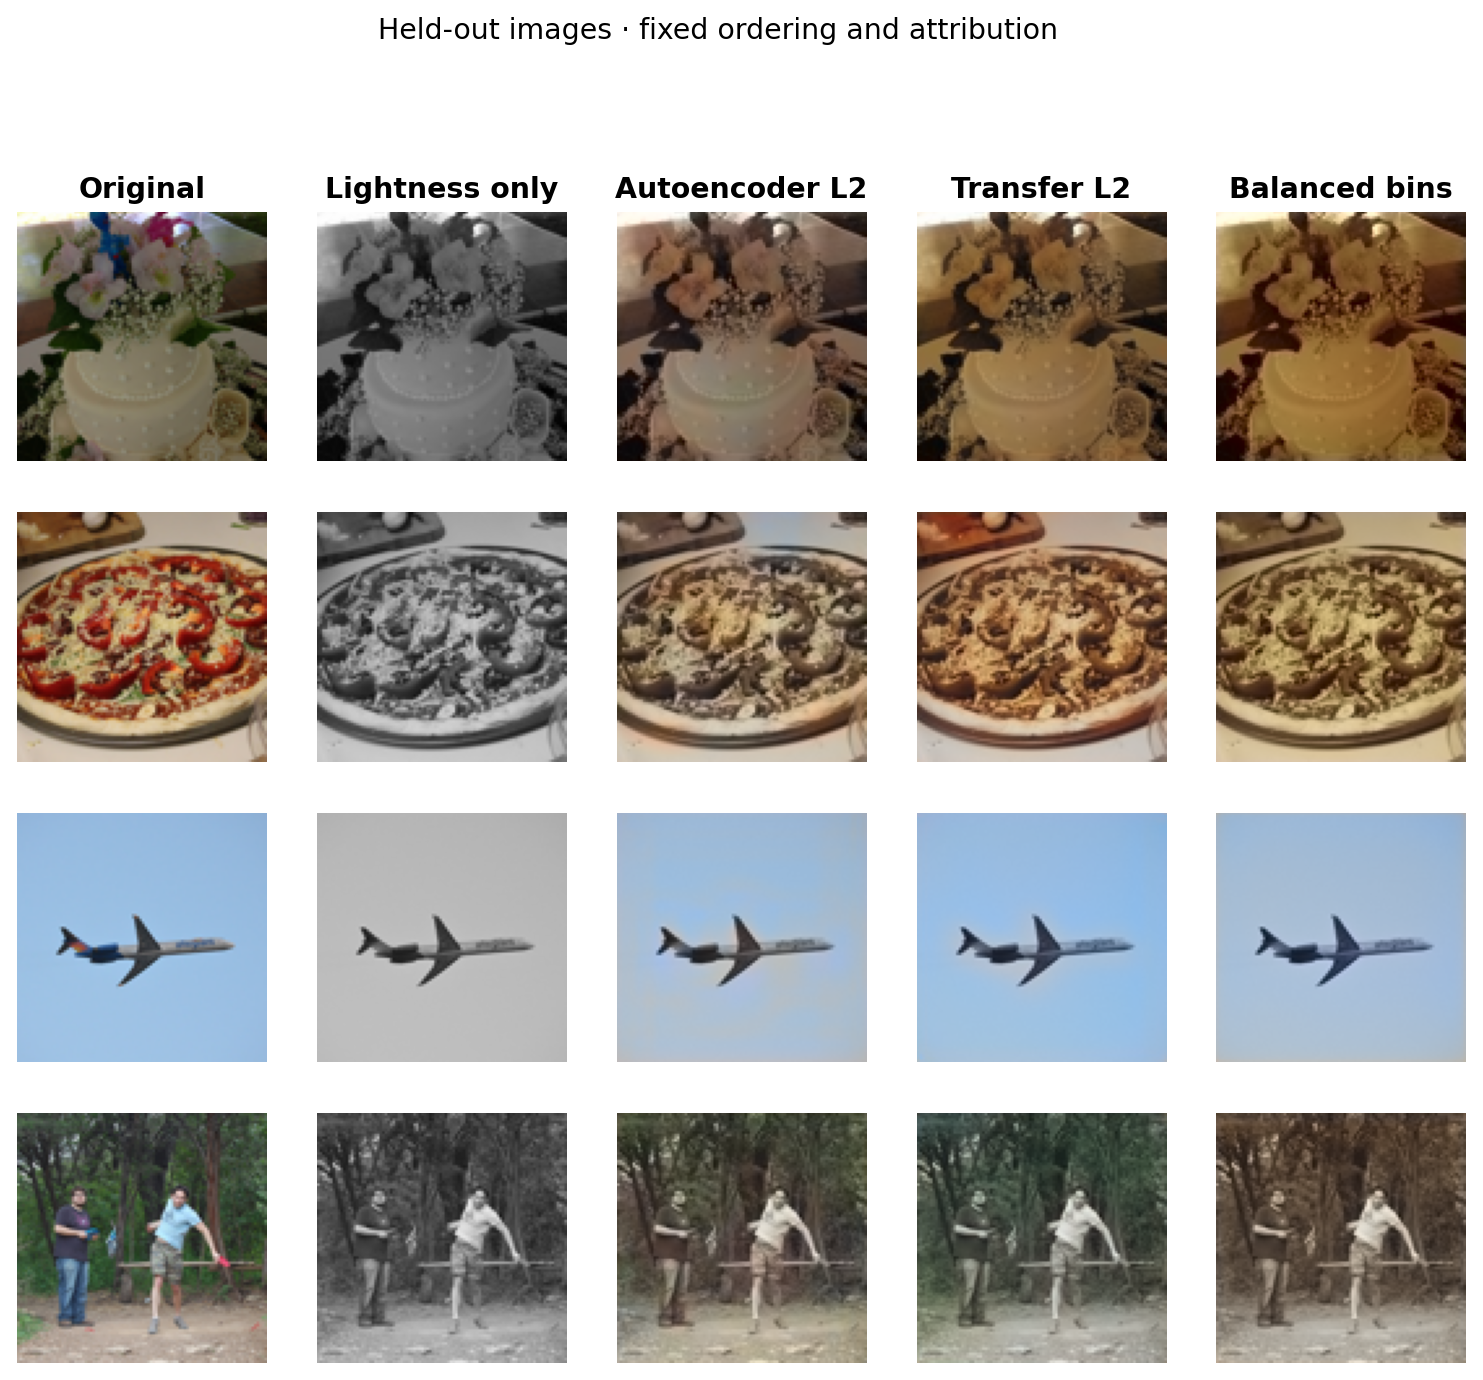

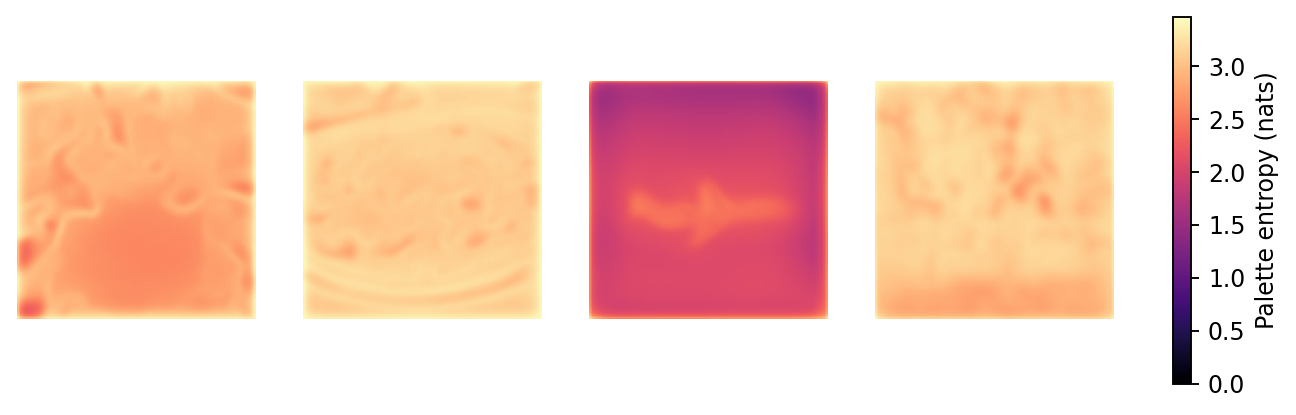

In [5]:
from IPython.display import Image, display
display(Image(filename=str(root/'assets/colorization_gallery.png')))
display(Image(filename=str(root/'assets/colorization_entropy.png')))

## Worked answer
        Does high entropy mean the RGB color is wrong? No. Entropy is uncertainty over
        this model's palette and depends on temperature. The palette distribution is not
        calibrated to human plausibility or true-color frequency. Evaluate exact-color
        errors, chroma and fixed examples together, and disclose external ImageNet exposure.